### Entrenamiento, ajuste y evaluación del SVM

Entrena el SVM que distingue tráfico benigno de tráfico de ataques *low and slow*, elige sus hiperparámetros y su umbral de decisión, lo evalúa con la partición de prueba y guarda los resultados.

**Entradas.** Las matrices que genera `02_Feature_Engineering.ipynb` en `data/processed/SVM/<variante>/`: características (`X_*`), etiquetas (`y_*`), metadatos (`meta_*`, con la etiqueta original y el bloque temporal de cada flujo) y `features.json`.

**Salidas**

- `models/svm/<variante>/svm_final.joblib`: modelo final con su umbral y la lista de características.
- `reports/svm/resultados_<variante>.json`: hiperparámetros, criterio de selección, métricas de validación y prueba, y análisis desagregados.
- `reports/svm/`: puntuaciones y predicciones por flujo de validación y prueba.
- `reports/figures/svm/<variante>/`: figuras y tablas de apoyo.

**Decisiones de diseño**

- **Fuga de información.** La transformación logarítmica con signo y la estandarización van dentro de un `Pipeline` con el clasificador. Así, en la validación cruzada sus parámetros se ajustan solo con los pliegues de ajuste y, en el modelo final, solo con el entrenamiento.
- **Desbalance de clases.** `class_weight` es un hiperparámetro de la búsqueda y el umbral se ajusta en validación. No se remuestrea de forma sintética: así se evita crear ejemplos artificiales y la fuga entre pliegues que provoca remuestrear antes de la validación cruzada.
- **Kernels.** Se comparan el lineal (con `LinearSVC`, apropiado para conjuntos grandes) y el RBF. El sigmoide se probó de forma preliminar, no mejoró a los otros dos y se dejó fuera; puede reincorporarse con `KERNELS`.
- **Costo.** Entrenar un SVM con kernel RBF crece aproximadamente con el cuadrado del número de ejemplos. Por eso la búsqueda usa una muestra estratificada de entrenamiento (`N_BUSQUEDA`) y el modelo final se entrena con `N_FINAL` filas; si ese valor alcanza el tamaño de la partición, se usa completa.

**Selección del modelo**

1. Cada configuración se evalúa con validación cruzada de pliegues temporales por bloque sobre la muestra de búsqueda. La métrica es AP (*average precision*, área bajo la curva precisión-recall; `pr_auc` en el código). Una validación cruzada aleatoria repartiría entre pliegues de ajuste y de evaluación flujos cercanos en el tiempo y muy parecidos, y daría estimaciones optimistas.
2. Dentro de cada kernel se aplica la regla de un error estándar (Hastie, Tibshirani y Friedman, 2009): entre las configuraciones cuyo AP medio no queda más de un error estándar por debajo del mejor (desviación entre pliegues dividida entre la raíz del número de pliegues), se elige la más simple. En RBF se ordena primero por `gamma`, porque un valor menor da una frontera más suave, y después por `C`, porque un valor menor regulariza más. En el kernel lineal se ordena por `C`.
3. El kernel se elige con la partición de validación, que es cronológicamente posterior al entrenamiento.

**Umbral.** Se elige en validación: el que maximiza F2 (da más peso al recall que a la precisión) entre los que alcanzan un recall mínimo de 0.75 sobre la clase de ataque, según el objetivo específico del protocolo.

**Evaluación.** Con modelo y umbral fijos se evalúa la prueba. Además de las métricas globales se reportan intervalos de confianza, el desempeño por tipo de ataque y por bloque, el desempeño sobre los vectores de prueba que no aparecen en entrenamiento y una línea base de una sola característica. `VARIANTE` elige el directorio de matrices de entrada.

**Contenido**

1. Carga y verificación de los datos
2. Muestras de búsqueda y de entrenamiento final
3. Pipeline y espacio de búsqueda
4. Búsqueda de hiperparámetros y regla de un error estándar
5. Selección del kernel en validación
6. Modelo final
7. Umbral de decisión
8. Línea base
9. Evaluación en prueba
10. Análisis desagregado en prueba
11. Guardado de resultados
12. Diagnóstico de generalización

El Anexo A documenta la configuración de mayor AP en la validación cruzada, que era el criterio de selección inicial. El Anexo B cuantifica los flujos sin carga útil y sin respuesta del servidor, y el desempeño del modelo sobre ellos.

In [2]:
# Librerías y parámetros del cuaderno. Todo valor ajustable está en esta celda
# y se registra en el JSON de resultados.

import sys
sys.path.append("../..")  # raíz del repositorio, desde notebooks/<carpeta>/

import json
import time
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, average_precision_score, confusion_matrix, f1_score, fbeta_score,
    precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import GridSearchCV, PredefinedSplit, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.svm import SVC, LinearSVC

# Transformación log con signo: sign(x) * log1p(|x|)
from src.preprocessing.clean import _log_con_signo

# Variante de las matrices de entrada: "completa" o "sin_init_win".
VARIANTE = "completa"

# Semilla de todos los procesos aleatorios.
RANDOM_STATE = 42

# Kernels incluidos en la búsqueda. El sigmoide puede añadirse como "sigmoid".
KERNELS = ["linear", "rbf"]

# Filas de las muestras estratificadas de entrenamiento: búsqueda y modelo final
N_BUSQUEDA = 50_000
N_FINAL = 400_000

# Pliegues de la validación cruzada
N_PLIEGUES = 3

# Criterio del umbral: F-beta máxima sujeta a un recall mínimo en validación
BETA = 2
RECALL_MINIMO = 0.75

# Característica de la línea base
FEATURE_LINEA_BASE = "Flow Duration"

# True entrena también la configuración de mayor AP en la validación cruzada (criterio
# inicial) para compararla con la elegida (Anexo A). Puede tardar más de una hora
EJECUTAR_ANEXO = False

# Rutas
DATA_DIR = Path("../../data/processed/SVM") / VARIANTE
MODEL_DIR = Path("../../models/svm") / VARIANTE
RES_DIR = Path("../../reports/svm")
FIG_DIR = Path("../../reports/figures/svm") / VARIANTE
for d in (MODEL_DIR, RES_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"Variante: {VARIANTE} | kernels: {KERNELS}")

Variante: completa | kernels: ['linear', 'rbf']


**1. Carga y verificación de los datos**

Se cargan matrices, etiquetas y metadatos de las tres particiones, junto con `features.json`. Antes de seguir se comprueba que las columnas coinciden con las registradas en ese archivo, que las longitudes son consistentes, que no hay nulos y que la etiqueta binaria concuerda con la etiqueta original de los metadatos. Así se asegura que el cuaderno trabaja con las matrices de la etapa anterior.

In [2]:
# Registro de características generado por 02_Feature_Engineering.ipynb
info_features = json.loads((DATA_DIR / "features.json").read_text(encoding="utf-8"))
caracteristicas = info_features["caracteristicas_finales"]

# Matriz, etiqueta y metadatos de una partición
def cargar_particion(nombre):
    X = pd.read_csv(DATA_DIR / f"X_{nombre}.csv")
    y = pd.read_csv(DATA_DIR / f"y_{nombre}.csv")["label_binaria"]
    meta = pd.read_csv(DATA_DIR / f"meta_{nombre}.csv")
    return X, y, meta

X_train, y_train, meta_train = cargar_particion("train")
X_val, y_val, meta_val = cargar_particion("val")
X_test, y_test, meta_test = cargar_particion("test")

# Coherencia de los datos cargados
for nombre, X, y, m in [("train", X_train, y_train, meta_train),
                        ("val", X_val, y_val, meta_val),
                        ("test", X_test, y_test, meta_test)]:
    assert list(X.columns) == caracteristicas, f"Las columnas de X_{nombre} no coinciden con features.json"
    assert len(X) == len(y) == len(m), f"Longitudes inconsistentes en {nombre}"
    assert not X.isna().any().any(), f"Valores nulos en X_{nombre}"
    assert set(y.unique()) <= {0, 1}, f"Etiqueta no binaria en {nombre}"
    assert ((m["Label"] != "BENIGN").astype(int) == y).all(), f"Etiqueta incoherente con Label en {nombre}"

print(f"Variante: {info_features['variante']} | características: {len(caracteristicas)} | "
      f"EPS de las derivadas: {info_features.get('eps')}")
for nombre, X, y in [("train", X_train, y_train), ("val", X_val, y_val), ("test", X_test, y_test)]:
    print(f"  {nombre:5s}: {len(X):>8,} filas | ataques: {int(y.sum()):>6,} ({y.mean():.4%})")

Variante: completa | características: 42 | EPS de las derivadas: 1.0
  train:  310,529 filas | ataques:  8,230 (2.6503%)
  val  :   66,541 filas | ataques:  1,884 (2.8313%)
  test :   66,544 filas | ataques:  1,175 (1.7657%)


**2. Muestras de búsqueda y de entrenamiento final**

Del entrenamiento se extraen dos muestras estratificadas por clase. La de `N_BUSQUEDA` filas se usa en la búsqueda de hiperparámetros, donde se ajustan muchas configuraciones y el costo del kernel RBF obliga a limitar el tamaño. La de `N_FINAL` filas, más grande, entrena el modelo final con la configuración ya elegida. Si el tamaño pedido alcanza el de la partición, se usa completa.

In [3]:
def muestra_estratificada(X, y, n, random_state=RANDOM_STATE):
    """Muestra de n filas estratificada por clase; si n >= len(X) devuelve todo."""
    if n >= len(X):
        return X, y
    X_m, _, y_m, _ = train_test_split(X, y, train_size=n, stratify=y, random_state=random_state)
    return X_m, y_m

X_busq, y_busq = muestra_estratificada(X_train, y_train, N_BUSQUEDA)
X_final, y_final = muestra_estratificada(X_train, y_train, N_FINAL)

print(f"Muestra de búsqueda:         {len(X_busq):>8,} filas | ataques: {y_busq.mean():.4%}")
print(f"Muestra de entrenamiento final: {len(X_final):>5,} filas | ataques: {y_final.mean():.4%}")

Muestra de búsqueda:           50,000 filas | ataques: 2.6500%
Muestra de entrenamiento final: 310,529 filas | ataques: 2.6503%


**3. Pipeline y espacio de búsqueda**

Cada configuración es un `Pipeline` de tres pasos: transformación logarítmica con signo, estandarización y clasificador (`LinearSVC` para el kernel lineal, `SVC` para los demás).

En el kernel lineal se exploran `C` y `class_weight`. En el RBF, `C`, `gamma` y `class_weight`. Con datos estandarizados, `gamma="scale"` de scikit-learn equivale a 1/(número de características), cerca de 0.02, así que la rejilla cubre valores por debajo y por encima. El sigmoide, opcional, usa los mismos hiperparámetros que el RBF. `SVC` no tiene límite de iteraciones, para que la optimización converja, y no se silencian los avisos de convergencia.

In [4]:
def construir_pipeline(kernel):
    """Pipeline: log con signo, estandarización y SVM con el kernel indicado."""
    if kernel == "linear":
        clf = LinearSVC(max_iter=20_000, random_state=RANDOM_STATE)
    else:
        clf = SVC(kernel=kernel, cache_size=2000)
    return Pipeline([
        ("log", FunctionTransformer(_log_con_signo, feature_names_out="one-to-one")),
        ("escala", StandardScaler()),
        ("clf", clf),
    ])

# Rejilla de hiperparámetros de cada kernel
REJILLAS = {
    "linear": {
        "clf__C": [0.001, 0.01, 0.1, 1, 10],
        "clf__class_weight": [None, "balanced"],
    },
    "rbf": {
        "clf__C": [0.01, 0.03, 0.1, 0.3, 1, 10, 100],
        "clf__gamma": [0.001, 0.01, 0.1, 1.0],
        "clf__class_weight": [None, "balanced"],
    },
    "sigmoid": {
        "clf__C": [0.1, 1, 10],
        "clf__gamma": [0.001, 0.01, 0.1],
        "clf__class_weight": [None, "balanced"],
    },
}

for k in KERNELS:
    n_config = int(np.prod([len(v) for v in REJILLAS[k].values()]))
    print(f"Kernel {k}: {n_config} configuraciones x {N_PLIEGUES} pliegues = {n_config * N_PLIEGUES} ajustes")

Kernel linear: 10 configuraciones x 3 pliegues = 30 ajustes
Kernel rbf: 56 configuraciones x 3 pliegues = 168 ajustes


**4. Búsqueda de hiperparámetros y regla de un error estándar**

Para cada kernel se hace una búsqueda exhaustiva (`GridSearchCV`) sobre la muestra de búsqueda. Cada configuración se evalúa con AP, calculado con la función de decisión del clasificador.

**Pliegues.** No se usa validación cruzada aleatoria, porque mezclaría flujos del mismo minuto, muy parecidos, entre ajuste y evaluación y sobrestimaría el desempeño. Tampoco `TimeSeriesSplit`, porque los ataques se concentran en dos ventanas y la mayoría de los pliegues de evaluación quedarían sin ataques. En su lugar, cada bloque temporal de entrenamiento se divide en `N_PLIEGUES` tramos contiguos y el pliegue *j* junta el tramo *j* de todos los bloques. Así cada pliegue contiene los dos tipos de ataque y los minutos de ajuste y de evaluación no se intercalan. Esto exige que las filas de entrenamiento conserven el orden cronológico dentro de cada bloque, y se verifica antes de la búsqueda.

**Regla de un error estándar.** `GridSearchCV` la aplica con `refit=regla_un_error_estandar`. La función toma la configuración de mayor AP medio y calcula su error estándar (desviación entre pliegues dividida entre la raíz del número de pliegues). Las configuraciones con AP medio mayor o igual al de la mejor menos ese error se consideran equivalentes, y entre ellas se elige la más simple: menor `gamma` y, a igualdad, menor `C`. Si aún hay empate, por ejemplo entre ponderaciones de clase, gana la de mayor AP medio. Por kernel se registran la configuración de mayor AP, la elegida y el tiempo de cómputo.

In [5]:

def regla_un_error_estandar(cv_results):
    """Regla de un error estándar, para el parámetro `refit` de GridSearchCV.

    Entre las configuraciones a menos de un error estándar de la de mayor AP medio, elige la más
    simple: menor gamma (frontera más suave) y, a igualdad, menor C (más regularización). Si
    persiste el empate, gana la de mayor AP medio.

    Args:
        cv_results: atributo `cv_results_` de GridSearchCV.

    Returns:
        Índice de la configuración elegida.
    """
    res = pd.DataFrame(cv_results)
    mejor = res["mean_test_score"].idxmax()
    limite = res.loc[mejor, "mean_test_score"] - res.loc[mejor, "std_test_score"] / np.sqrt(N_PLIEGUES)
    candidatas = res[res["mean_test_score"] >= limite]
    orden = pd.DataFrame({
        "gamma": candidatas["params"].apply(lambda p: p.get("clf__gamma", 0.0)),
        "C": candidatas["params"].apply(lambda p: p["clf__C"]),
        "menos_score": -candidatas["mean_test_score"],
    }, index=candidatas.index)
    return int(orden.sort_values(["gamma", "C", "menos_score"]).index[0])


# Pliegues temporales por bloque, iguales para todos los kernels.
# Se asume que las filas de entrenamiento están ordenadas por bloque
assert meta_train["bloque"].is_monotonic_increasing, (
    "Las filas de entrenamiento no están ordenadas por bloque; regenerar con Feature_Engineering.ipynb")

# Cada bloque se corta en N_PLIEGUES tramos contiguos según la posición de la fila en el bloque
posicion = meta_train.groupby("bloque").cumcount()
tamano = meta_train.groupby("bloque")["bloque"].transform("size")
pliegue_train = (posicion * N_PLIEGUES // tamano).to_numpy()

# Pliegue de cada fila de la muestra de búsqueda (su índice es la posición en entrenamiento).
pliegue_busq = pliegue_train[X_busq.index.to_numpy()]
cv = PredefinedSplit(pliegue_busq)

# Cada pliegue debe tener ejemplos de ambos tipos de ataque
composicion = pd.crosstab(pd.Series(pliegue_busq, name="pliegue"),
                          meta_train.loc[X_busq.index, "Label"].to_numpy())
print("Composición de los pliegues de la muestra de búsqueda:")
display(composicion)
ataques = [c for c in composicion.columns if c != "BENIGN"]
assert (composicion[ataques] > 0).all().all(), "Algún pliegue no contiene ejemplos de algún tipo de ataque"

# Búsqueda por kernel; refit elige la configuración con la regla de un error estándar
busquedas, tiempos_busqueda, config_max_pr_auc = {}, {}, {}
for k in KERNELS:
    gs = GridSearchCV(
        estimator=construir_pipeline(k),
        param_grid=REJILLAS[k],
        scoring="average_precision",
        cv=cv,
        n_jobs=-1,
        refit=regla_un_error_estandar,
        verbose=1,
    )
    inicio = time.time()
    gs.fit(X_busq, y_busq)
    tiempos_busqueda[k] = time.time() - inicio
    busquedas[k] = gs

    # Configuración de mayor AP (criterio inicial), para compararla con la elegida por la regla
    res = pd.DataFrame(gs.cv_results_)
    i_max = int(res["mean_test_score"].idxmax())
    config_max_pr_auc[k] = res.loc[i_max, "params"]
    limite = res.loc[i_max, "mean_test_score"] - res.loc[i_max, "std_test_score"] / np.sqrt(N_PLIEGUES)
    n_equivalentes = int((res["mean_test_score"] >= limite).sum())

    print(f"\nKernel {k} | tiempo de búsqueda: {tiempos_busqueda[k] / 60:.1f} min")
    print(f"  Mayor PR-AUC:   {res.loc[i_max, 'mean_test_score']:.4f} ± {res.loc[i_max, 'std_test_score']:.4f} "
          f"| {config_max_pr_auc[k]}")
    print(f"  Límite de la regla: {limite:.4f} | configuraciones equivalentes: {n_equivalentes}")
    print(f"  Seleccionada:   {res.loc[gs.best_index_, 'mean_test_score']:.4f} "
          f"± {res.loc[gs.best_index_, 'std_test_score']:.4f} | {gs.best_params_}")


Composición de los pliegues de la muestra de búsqueda:


col_0,BENIGN,DoS Slowhttptest,DoS slowloris
pliegue,,,
0,16140,174,261
1,16306,238,225
2,16229,257,170


Fitting 3 folds for each of 10 candidates, totalling 30 fits

Kernel linear | tiempo de búsqueda: 0.2 min
  Mayor PR-AUC:   0.9199 ± 0.0447 | {'clf__C': 0.1, 'clf__class_weight': None}
  Límite de la regla: 0.8941 | configuraciones equivalentes: 8
  Seleccionada:   0.9055 ± 0.0436 | {'clf__C': 0.01, 'clf__class_weight': None}
Fitting 3 folds for each of 56 candidates, totalling 168 fits

Kernel rbf | tiempo de búsqueda: 5.6 min
  Mayor PR-AUC:   0.9832 ± 0.0039 | {'clf__C': 1, 'clf__class_weight': None, 'clf__gamma': 1.0}
  Límite de la regla: 0.9810 | configuraciones equivalentes: 7
  Seleccionada:   0.9813 ± 0.0054 | {'clf__C': 1, 'clf__class_weight': None, 'clf__gamma': 0.1}


In [6]:

# Ranking de configuraciones por kernel, marcando las equivalentes a la mejor (regla de un
# error estándar) y la elegida
def tabla_ranking(gs):
    res = pd.DataFrame(gs.cv_results_)
    i_max = res["mean_test_score"].idxmax()
    limite = res.loc[i_max, "mean_test_score"] - res.loc[i_max, "std_test_score"] / np.sqrt(N_PLIEGUES)    
    return pd.DataFrame({
        "puesto": res["rank_test_score"],
        "C": res["params"].apply(lambda p: p["clf__C"]),
        "gamma": res["params"].apply(lambda p: p.get("clf__gamma", np.nan)),
        "class_weight": res["params"].apply(lambda p: str(p["clf__class_weight"])),
        "pr_auc_cv": res["mean_test_score"],
        "std": res["std_test_score"],
        "equivalente_a_la_mejor": res["mean_test_score"] >= limite,
        "seleccionada": res.index == gs.best_index_,
    }).sort_values("puesto")


for k, gs in busquedas.items():
    t = tabla_ranking(gs)
    t.to_csv(FIG_DIR / f"ranking_validacion_cruzada_{k}.csv", index=False)
    print(f"\nKernel {k}: configuraciones equivalentes a la mejor y siguientes")
    display(t.head(max(15, int(t["equivalente_a_la_mejor"].sum()) + 3)).round(4))



Kernel linear: configuraciones equivalentes a la mejor y siguientes


,puesto,C,gamma,class_weight,pr_auc_cv,std,equivalente_a_la_mejor,seleccionada
4,1,0.100,NaN,None,0.9199,0.0447,True,False
6,2,1.000,NaN,None,0.9158,0.0389,True,False
8,3,10.000,NaN,None,0.9100,0.0288,True,False
2,4,0.010,NaN,None,0.9055,0.0436,True,True
5,5,0.100,NaN,balanced,0.9019,0.0339,True,False
9,6,10.000,NaN,balanced,0.8977,0.0270,True,False
7,7,1.000,NaN,balanced,0.8968,0.0380,True,False
3,8,0.010,NaN,balanced,0.8965,0.0270,True,False
0,9,0.001,NaN,None,0.8601,0.0399,False,False
1,10,0.001,NaN,balanced,0.8417,0.0380,False,False



Kernel rbf: configuraciones equivalentes a la mejor y siguientes


,puesto,C,gamma,class_weight,pr_auc_cv,std,equivalente_a_la_mejor,seleccionada
35,1,1.00,1.0,None,0.9832,0.0039,True,False
23,2,0.10,1.0,balanced,0.9828,0.0030,True,False
15,3,0.03,1.0,balanced,0.9823,0.0036,True,False
31,4,0.30,1.0,balanced,0.9823,0.0043,True,False
27,5,0.30,1.0,None,0.9818,0.0034,True,False
34,6,1.00,0.1,None,0.9813,0.0054,True,True
39,7,1.00,1.0,balanced,0.9812,0.0045,True,False
43,8,10.00,1.0,None,0.9809,0.0058,False,False
47,9,10.00,1.0,balanced,0.9803,0.0047,False,False
7,10,0.01,1.0,balanced,0.9791,0.0027,False,False


**5. Selección del kernel en validación**

La configuración elegida de cada kernel, ajustada sobre la muestra de búsqueda, se evalúa en validación con AP y ROC-AUC, dos métricas que no dependen del umbral. Se elige el kernel con mayor AP en validación. Si existe una corrida anterior de esta variante, también se compara la configuración elegida con la de esa corrida.

In [7]:
# Configuración elegida de cada kernel, evaluada en validación
filas = []
for k, gs in busquedas.items():
    puntuacion = gs.best_estimator_.decision_function(X_val)
    filas.append({
        "kernel": k,
        "params": {p.replace("clf__", ""): v for p, v in gs.best_params_.items()},
        "pr_auc_cv": gs.cv_results_["mean_test_score"][gs.best_index_],
        "pr_auc_val": average_precision_score(y_val, puntuacion),
        "roc_auc_val": roc_auc_score(y_val, puntuacion),
    })
seleccion_kernel = pd.DataFrame(filas).sort_values("pr_auc_val", ascending=False).reset_index(drop=True)
display(seleccion_kernel.round(4))

# Kernel de mayor AP en validación
KERNEL_ELEGIDO = seleccion_kernel.loc[0, "kernel"]
busqueda_elegida = busquedas[KERNEL_ELEGIDO]
print(f"Kernel seleccionado: {KERNEL_ELEGIDO} | hiperparámetros: {seleccion_kernel.loc[0, 'params']}")

# Comparación con la corrida anterior de esta variante, si existe. Si la configuración
# coincide, el modelo final y los resultados de prueba no cambian; si difiere, hay que
# documentar el cambio
ruta_previa = RES_DIR / f"resultados_{VARIANTE}.json"
if ruta_previa.exists():
    previo = json.loads(ruta_previa.read_text(encoding="utf-8"))
    actual = {"kernel": KERNEL_ELEGIDO, **seleccion_kernel.loc[0, "params"]}
    anterior = {"kernel": previo.get("kernel_seleccionado"), **previo.get("hiperparametros", {})}
    print(f"\nConfiguración de la corrida anterior: {anterior}")
    print(f"Configuración actual:                {actual}")
    print("La configuración coincide con la anterior." if actual == anterior
          else "La configuración cambió respecto de la corrida anterior.")


,kernel,params,pr_auc_cv,pr_auc_val,roc_auc_val
0,rbf,"{'C': 1, 'class_weight': None, 'gamma': 0.1}",0.9813,0.9949,0.9997
1,linear,"{'C': 0.01, 'class_weight': None}",0.9055,0.9767,0.9994


Kernel seleccionado: rbf | hiperparámetros: {'C': 1, 'class_weight': None, 'gamma': 0.1}

Configuración de la corrida anterior: {'kernel': 'rbf', 'C': 1, 'class_weight': None, 'gamma': 0.1}
Configuración actual:                {'kernel': 'rbf', 'C': 1, 'class_weight': None, 'gamma': 0.1}
La configuración coincide con la anterior.


**6. Modelo final**

Con la configuración elegida se ajusta un pipeline nuevo sobre la muestra de entrenamiento final, de modo que todos sus parámetros (transformación, estandarización y clasificador) se estiman solo con esa muestra.

In [8]:
# clone() parte de un pipeline sin ajustar, con los hiperparámetros elegidos
modelo_final = clone(busqueda_elegida.best_estimator_)
inicio = time.time()
modelo_final.fit(X_final, y_final)
tiempo_final = time.time() - inicio

clasificador = modelo_final.named_steps["clf"]
n_soporte = int(clasificador.n_support_.sum()) if hasattr(clasificador, "n_support_") else None
print(f"Tiempo de entrenamiento del modelo final: {tiempo_final / 60:.1f} min")
if n_soporte is not None:
    print(f"Vectores de soporte: {n_soporte:,}")

Tiempo de entrenamiento del modelo final: 3.8 min
Vectores de soporte: 1,314


**7. Umbral de decisión**

El clasificador produce una función de decisión continua, con 0 como umbral por defecto. En validación se recorren todos los umbrales posibles y se elige el que maximiza F con β = `BETA` entre los que alcanzan un recall de al menos `RECALL_MINIMO`. Se reportan las métricas de validación con el umbral por defecto y con el elegido, y la curva precisión-recall con ambos puntos.

,umbral_predeterminado (0),umbral_seleccionado (-0.8320)
accuracy,0.9974,0.9994
precision,0.9880,0.9817
recall,0.9177,0.9984
f1,0.9516,0.9900
f2,0.9310,0.9950
tasa_falsos_positivos,0.0003,0.0005
tp,1729.0000,1881.0000
fp,21.0000,35.0000
fn,155.0000,3.0000
tn,64636.0000,64622.0000


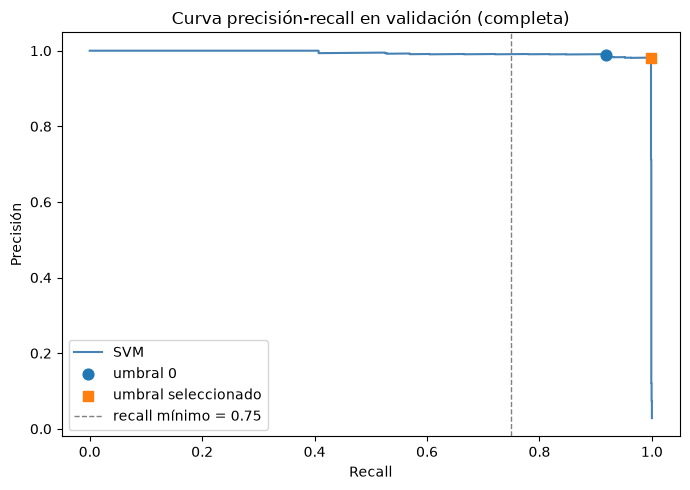

In [9]:
def elegir_umbral(y, puntuacion, beta=BETA, recall_minimo=RECALL_MINIMO):
    """Umbral que maximiza F-beta entre los que alcanzan el recall mínimo.

    Args:
        y: etiquetas binarias.
        puntuacion: función de decisión (mayor = más probable ataque).
        beta: peso del recall en F-beta.
        recall_minimo: recall mínimo exigido sobre la clase de ataque.

    Raises:
        ValueError: si ningún umbral alcanza el recall mínimo.
    """
    p, r, t = precision_recall_curve(y, puntuacion)
    p, r = p[:-1], r[:-1]  # precision_recall_curve devuelve un punto más que umbrales
    f_beta = (1 + beta**2) * p * r / np.maximum(beta**2 * p + r, 1e-12)
    validos = r >= recall_minimo
    if not validos.any():
        raise ValueError(f"Ningún umbral alcanza un recall de {recall_minimo}")
    i = int(np.argmax(np.where(validos, f_beta, -1.0)))
    return float(t[i])


def metricas(y, puntuacion, umbral):
    """Métricas de clasificación con la regla `puntuacion >= umbral`.

    ROC-AUC y AP (`pr_auc`) no dependen del umbral y solo se calculan si `y` tiene las dos clases.
    """
    y = np.asarray(y)
    pred = (np.asarray(puntuacion) >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    resultado = {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        f"f{BETA}": fbeta_score(y, pred, beta=BETA, zero_division=0),
        "tasa_falsos_positivos": fp / (fp + tn) if (fp + tn) else np.nan,
        "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
    }
    if len(np.unique(y)) == 2:
        resultado["roc_auc"] = roc_auc_score(y, puntuacion)
        resultado["pr_auc"] = average_precision_score(y, puntuacion)
    return resultado


# El umbral se elige solo con validación
puntuacion_val = modelo_final.decision_function(X_val)
UMBRAL = elegir_umbral(y_val, puntuacion_val)

metricas_val = pd.DataFrame({
    "umbral_predeterminado (0)": metricas(y_val, puntuacion_val, 0.0),
    f"umbral_seleccionado ({UMBRAL:.4f})": metricas(y_val, puntuacion_val, UMBRAL),
})
display(metricas_val.round(4))

# Curva precisión-recall de validación con los dos puntos de operación.
p, r, _ = precision_recall_curve(y_val, puntuacion_val)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(r, p, color="steelblue", label="SVM")
for umbral, marcador, etiqueta in [(0.0, "o", "umbral 0"), (UMBRAL, "s", "umbral seleccionado")]:
    m = metricas(y_val, puntuacion_val, umbral)
    ax.scatter(m["recall"], m["precision"], marker=marcador, s=60, zorder=3, label=etiqueta)
ax.axvline(RECALL_MINIMO, color="gray", ls="--", lw=1, label=f"recall mínimo = {RECALL_MINIMO}")
ax.set_xlabel("Recall")
ax.set_ylabel("Precisión")
ax.set_title(f"Curva precisión-recall en validación ({VARIANTE})")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "curva_pr_validacion.png", dpi=150)
plt.show()

**8. Línea base**

Referencia sencilla para dimensionar lo que aporta el SVM: se clasifica cada flujo con un umbral sobre una sola característica (`FEATURE_LINEA_BASE`). La orientación de la regla (si valores altos o bajos indican ataque) se determina con la muestra de búsqueda y el umbral se elige en validación con el mismo criterio que el del SVM.

In [10]:
# Orientación de la regla (valores altos o bajos = ataque), con la muestra de búsqueda
signo_base = 1.0 if roc_auc_score(y_busq, X_busq[FEATURE_LINEA_BASE]) >= 0.5 else -1.0

# Umbral de la línea base elegido en validación, igual que el del SVM
puntuacion_base_val = signo_base * X_val[FEATURE_LINEA_BASE].to_numpy(dtype=float)
UMBRAL_BASE = elegir_umbral(y_val, puntuacion_base_val)

print(f"Línea base: {'+' if signo_base > 0 else '-'}{FEATURE_LINEA_BASE} >= {UMBRAL_BASE:.4f}")
display(pd.Series(metricas(y_val, puntuacion_base_val, UMBRAL_BASE), name="línea base (validación)").round(4))

Línea base: +Flow Duration >= 2999846.0000


accuracy                     0.8138
precision                    0.1170
recall                       0.8514
f1                           0.2057
f2                           0.3775
tasa_falsos_positivos        0.1872
tp                        1604.0000
fp                       12107.0000
fn                         280.0000
tn                       52550.0000
roc_auc                      0.8025
pr_auc                       0.1241
Name: línea base (validación), dtype: float64

**9. Evaluación en prueba**

Estima el desempeño con datos que no intervinieron en ninguna decisión anterior. La prueba se evalúa una sola vez, con el modelo y el umbral ya fijados. Se calculan las métricas con el umbral elegido (punto de operación principal) y con el umbral 0 como referencia, junto con las de la línea base. Para recall y precisión se dan intervalos de Wilson al 95 %, porque en esta partición hay pocos ataques. También se presentan la matriz de confusión y las curvas ROC y precisión-recall.

In [11]:
def intervalo_wilson(k, n, z=1.96):
    """Intervalo de Wilson para la proporción k/n (z = 1.96 equivale a 95 %)."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denominador = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / denominador
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominador
    return (centro - margen, centro + margen)


# La prueba se puntúa una sola vez, con el modelo y el umbral ya fijados
puntuacion_test = modelo_final.decision_function(X_test)
puntuacion_base_test = signo_base * X_test[FEATURE_LINEA_BASE].to_numpy(dtype=float)

m_test = metricas(y_test, puntuacion_test, UMBRAL)
m_test_0 = metricas(y_test, puntuacion_test, 0.0)
m_base_test = metricas(y_test, puntuacion_base_test, UMBRAL_BASE)

display(pd.DataFrame({
    "SVM (umbral seleccionado)": m_test,
    "SVM (umbral 0)": m_test_0,
    "línea base": m_base_test,
}).round(4))

# Intervalos de Wilson de recall y precisión con el umbral elegido
ic_recall = intervalo_wilson(m_test["tp"], m_test["tp"] + m_test["fn"])
ic_precision = intervalo_wilson(m_test["tp"], m_test["tp"] + m_test["fp"])
print(f"Recall:    {m_test['recall']:.4f}  IC 95 % [{ic_recall[0]:.4f}, {ic_recall[1]:.4f}]")
print(f"Precisión: {m_test['precision']:.4f}  IC 95 % [{ic_precision[0]:.4f}, {ic_precision[1]:.4f}]")

,SVM (umbral seleccionado),SVM (umbral 0),línea base
accuracy,0.9994,0.9971,0.7821
precision,0.9765,0.9871,0.0562
recall,0.9898,0.8451,0.7174
f1,0.9831,0.9106,0.1042
f2,0.9871,0.8701,0.2139
tasa_falsos_positivos,0.0004,0.0002,0.2167
tp,1163.0000,993.0000,843.0000
fp,28.0000,13.0000,14165.0000
fn,12.0000,182.0000,332.0000
tn,65341.0000,65356.0000,51204.0000


Recall:    0.9898  IC 95 % [0.9822, 0.9941]
Precisión: 0.9765  IC 95 % [0.9662, 0.9837]


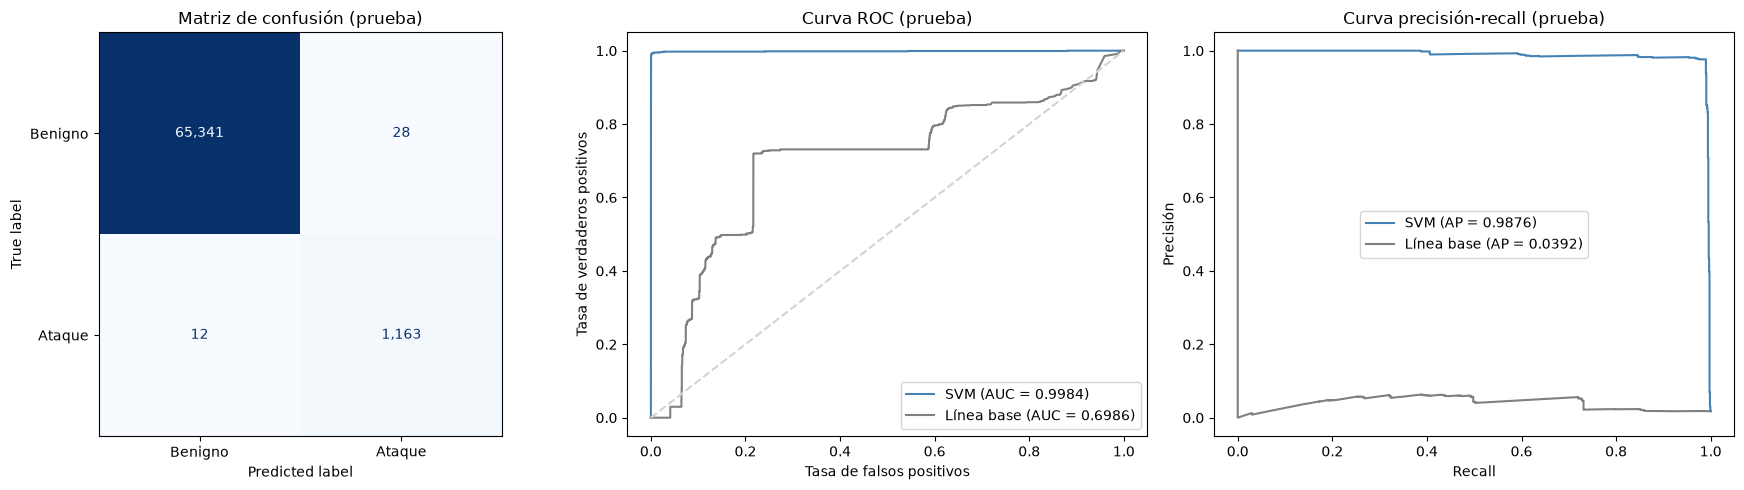

In [12]:
# Matriz de confusión (umbral elegido) y curvas ROC y precisión-recall en prueba
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pred_test = (puntuacion_test >= UMBRAL).astype(int)
ConfusionMatrixDisplay(
    confusion_matrix(y_test, pred_test, labels=[0, 1]), display_labels=["Benigno", "Ataque"]
).plot(ax=axes[0], cmap="Blues", values_format=",d", colorbar=False)
axes[0].set_title("Matriz de confusión (prueba)")

for puntuacion, etiqueta, color in [(puntuacion_test, "SVM", "steelblue"),
                                    (puntuacion_base_test, "Línea base", "gray")]:
    fpr, tpr, _ = roc_curve(y_test, puntuacion)
    axes[1].plot(fpr, tpr, color=color, label=f"{etiqueta} (AUC = {roc_auc_score(y_test, puntuacion):.4f})")
    p, r, _ = precision_recall_curve(y_test, puntuacion)
    axes[2].plot(r, p, color=color, label=f"{etiqueta} (AP = {average_precision_score(y_test, puntuacion):.4f})")
axes[1].plot([0, 1], [0, 1], color="lightgray", ls="--")
axes[1].set_xlabel("Tasa de falsos positivos")
axes[1].set_ylabel("Tasa de verdaderos positivos")
axes[1].set_title("Curva ROC (prueba)")
axes[1].legend()
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precisión")
axes[2].set_title("Curva precisión-recall (prueba)")
axes[2].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / "evaluacion_prueba.png", dpi=150)
plt.show()

**10. Análisis desagregado en prueba**

Revisa si el desempeño global esconde diferencias entre grupos de flujos. Con el umbral elegido se desglosa por:

1. **Tipo de ataque:** recall de Slowloris y de Slowhttptest por separado, con intervalo de confianza.
2. **Bloque temporal:** recall en los bloques con ataques y tasa de falsos positivos en cada bloque. Los bloques 2 y 4 son las ventanas de ataque, donde el tráfico benigno convive con el malicioso.
3. **Vectores no vistos en entrenamiento:** métricas solo sobre los flujos de prueba cuyo vector de características no está en entrenamiento, para descartar que el desempeño venga de memorizar vectores repetidos.

In [13]:
# 1. Recall por tipo de ataque.
filas = []
for etiqueta in sorted(meta_test.loc[meta_test["Label"] != "BENIGN", "Label"].unique()):
    mascara = (meta_test["Label"] == etiqueta).to_numpy()
    detectados = int(pred_test[mascara].sum())
    total = int(mascara.sum())
    ic = intervalo_wilson(detectados, total)
    filas.append({"ataque": etiqueta, "flujos": total, "detectados": detectados,
                  "recall": detectados / total, "ic95_inf": ic[0], "ic95_sup": ic[1]})
por_ataque = pd.DataFrame(filas)
print("Recall por tipo de ataque (prueba):")
display(por_ataque.round(4))

# 2. Desempeño por bloque temporal.
filas = []
for bloque in sorted(meta_test["bloque"].unique()):
    mascara = (meta_test["bloque"] == bloque).to_numpy()
    y_b, pred_b = y_test.to_numpy()[mascara], pred_test[mascara]
    n_ataques, n_benignos = int(y_b.sum()), int((y_b == 0).sum())
    filas.append({
        "bloque": int(bloque), "flujos": int(mascara.sum()), "ataques": n_ataques,
        "recall": pred_b[y_b == 1].mean() if n_ataques else np.nan,
        "falsos_positivos": int(pred_b[y_b == 0].sum()),
        "tasa_falsos_positivos": pred_b[y_b == 0].mean() if n_benignos else np.nan,
    })
por_bloque = pd.DataFrame(filas)
print("\nDesempeño por bloque temporal (prueba):")
display(por_bloque.round(4))

# 3. Vectores de prueba que no aparecen en entrenamiento (se compara el hash de cada fila)
hash_train = set(pd.util.hash_pandas_object(X_train, index=False).to_numpy())
no_visto = ~pd.util.hash_pandas_object(X_test, index=False).isin(hash_train).to_numpy()
m_test_no_visto = metricas(y_test[no_visto], puntuacion_test[no_visto], UMBRAL)
print(f"\nFlujos de prueba no vistos en entrenamiento: {int(no_visto.sum()):,} de {len(X_test):,} "
      f"(ataques: {int(y_test[no_visto].sum()):,})")
display(pd.DataFrame({"prueba completa": m_test, "prueba sin vectores vistos": m_test_no_visto}).round(4))

Recall por tipo de ataque (prueba):


,ataque,flujos,detectados,recall,ic95_inf,ic95_sup
0,DoS Slowhttptest,260,254,0.9769,0.9506,0.9894
1,DoS slowloris,915,909,0.9934,0.9858,0.9970



Desempeño por bloque temporal (prueba):


,bloque,flujos,ataques,recall,falsos_positivos,tasa_falsos_positivos
0,1,8007,0,NaN,4,0.0005
1,2,4555,915,0.9934,0,0.0000
2,3,536,0,NaN,0,0.0000
3,4,4981,260,0.9769,5,0.0011
4,5,48465,0,NaN,19,0.0004



Flujos de prueba no vistos en entrenamiento: 58,405 de 66,544 (ataques: 1,142)


,prueba completa,prueba sin vectores vistos
accuracy,0.9994,0.9993
precision,0.9765,0.9758
recall,0.9898,0.9895
f1,0.9831,0.9826
f2,0.9871,0.9867
tasa_falsos_positivos,0.0004,0.0005
tp,1163.0000,1130.0000
fp,28.0000,28.0000
fn,12.0000,12.0000
tn,65341.0000,57235.0000


**11. Guardado de resultados**

Se guarda el modelo final junto con su umbral, kernel, hiperparámetros y lista de características, de modo que pueda aplicarse a datos nuevos sin información adicional. Los parámetros del procedimiento y todas las métricas van a un JSON. Las puntuaciones y predicciones por flujo de validación y prueba se guardan con su etiqueta original y su bloque, para compararlas con los demás modelos.

In [15]:
# (a) Modelo con su umbral y lo necesario para aplicarlo a datos nuevos
paquete_modelo = {
    "pipeline": modelo_final,
    "umbral": UMBRAL,
    "kernel": KERNEL_ELEGIDO,
    "hiperparametros": seleccion_kernel.loc[0, "params"],
    "caracteristicas": caracteristicas,
    "variante": VARIANTE,
}
ruta_modelo = MODEL_DIR / "svm_final.joblib"
joblib.dump(paquete_modelo, ruta_modelo)

# (b) Resultados del procedimiento.
resultados = {
    "variante": VARIANTE,
    "kernels_evaluados": KERNELS,
    "kernel_seleccionado": KERNEL_ELEGIDO,
    "hiperparametros": seleccion_kernel.loc[0, "params"],
    "seleccion_kernel": seleccion_kernel.to_dict(orient="records"),
    "n_busqueda": len(X_busq), "n_final": len(X_final), "n_pliegues": N_PLIEGUES,
    "validacion_cruzada": "pliegues temporales por bloque (PredefinedSplit)",
    "criterio_seleccion_hiperparametros": "regla de un error estándar (menor gamma y, a igualdad, menor C)",
    "configuracion_mayor_pr_auc_cv": config_max_pr_auc,
    "tiempo_busqueda_s": tiempos_busqueda, "tiempo_entrenamiento_final_s": tiempo_final,
    "vectores_soporte": n_soporte,
    "criterio_umbral": {"beta": BETA, "recall_minimo": RECALL_MINIMO},
    "umbral": UMBRAL,
    "metricas_validacion": metricas(y_val, puntuacion_val, UMBRAL),
    "metricas_prueba": m_test,
    "metricas_prueba_umbral_0": m_test_0,
    "metricas_prueba_no_vistos": m_test_no_visto,
    "ic95_prueba": {"recall": ic_recall, "precision": ic_precision},
    "recall_por_ataque": por_ataque.to_dict(orient="records"),
    "desempeno_por_bloque": por_bloque.to_dict(orient="records"),
    "linea_base": {"feature": FEATURE_LINEA_BASE, "signo": signo_base, "umbral": UMBRAL_BASE,
                   "metricas_prueba": m_base_test},
    "random_state": RANDOM_STATE,
}
convertir = lambda o: o.item() if hasattr(o, "item") else (list(o) if isinstance(o, tuple) else str(o))
ruta_resultados = RES_DIR / f"resultados_{VARIANTE}.json"
ruta_resultados.write_text(json.dumps(resultados, indent=2, ensure_ascii=False, default=convertir),
                           encoding="utf-8")

# (c) Puntuaciones y predicciones por flujo.
for nombre, puntuacion, y, m in [("val", puntuacion_val, y_val, meta_val),
                                 ("test", puntuacion_test, y_test, meta_test)]:
    pd.DataFrame({
        "puntuacion": puntuacion,
        "prediccion": (puntuacion >= UMBRAL).astype(int),
        "label_binaria": y.to_numpy(),
        "Label": m["Label"].to_numpy(),
        "bloque": m["bloque"].to_numpy(),
    }).to_csv(RES_DIR / f"predicciones_{VARIANTE}_{nombre}.csv", index=False)

print(f"Modelo:      {ruta_modelo.resolve()}")
print(f"Resultados:  {ruta_resultados.resolve()}")
print(f"Predicciones: {RES_DIR.resolve()}")

Modelo:      C:\Users\juans\OneDrive\Documents\Github\low-and-slow-ids\models\svm\completa\svm_final.joblib
Resultados:  C:\Users\juans\OneDrive\Documents\Github\low-and-slow-ids\reports\svm\resultados_completa.json
Predicciones: C:\Users\juans\OneDrive\Documents\Github\low-and-slow-ids\reports\svm


In [16]:
# Resumen en prueba con el umbral elegido en validación
resumen_prueba = pd.Series({
    "Precisión": m_test["precision"],
    "Recall": m_test["recall"],
    "F1": m_test["f1"],
    f"F{BETA}": m_test[f"f{BETA}"],
    "Exactitud": m_test["accuracy"],
    "Tasa de falsos positivos": m_test["tasa_falsos_positivos"],
    "ROC-AUC": m_test["roc_auc"],
    "PR-AUC": m_test["pr_auc"],
}, name="Prueba")
display(resumen_prueba.round(4).to_frame())

print(f"Verdaderos positivos: {m_test['tp']:,} | Falsos negativos: {m_test['fn']:,}")
print(f"Falsos positivos:     {m_test['fp']:,} | Verdaderos negativos: {m_test['tn']:,}")
print(f"Recall:    {m_test['recall']:.4f}  IC 95 % [{ic_recall[0]:.4f}, {ic_recall[1]:.4f}]")
print(f"Precisión: {m_test['precision']:.4f}  IC 95 % [{ic_precision[0]:.4f}, {ic_precision[1]:.4f}]")

,Prueba
Precisión,0.9765
Recall,0.9898
F1,0.9831
F2,0.9871
Exactitud,0.9994
Tasa de falsos positivos,0.0004
ROC-AUC,0.9984
PR-AUC,0.9876


Verdaderos positivos: 1,163 | Falsos negativos: 12
Falsos positivos:     28 | Verdaderos negativos: 65,341
Recall:    0.9898  IC 95 % [0.9822, 0.9941]
Precisión: 0.9765  IC 95 % [0.9662, 0.9837]


**12. Diagnóstico de generalización**

Busca indicios de sobreajuste:

1. **Entrenamiento, validación y prueba:** se compara el desempeño con el mismo umbral. Una diferencia marcada entre entrenamiento y las otras particiones indicaría memorización.
2. **Vectores de soporte:** proporción de cada clase que el modelo usa como vectores de soporte. Una proporción alta indicaría una frontera demasiado pegada a los ejemplos.
3. **Recall por tramo de ataque:** dentro de cada ventana (bloques 2 y 4), dividida en cinco tramos consecutivos, en validación y prueba. Permite ver fallos concentrados en un momento del ataque.
4. **Falsos positivos por bloque** y desempeño en prueba **sin los vectores vistos en entrenamiento**.
5. **Curva de validación de `gamma`** (solo si el kernel es RBF): AP de la validación cruzada para cada `gamma`, con el `C` y el `class_weight` de la configuración elegida, para ver cómo cambia el desempeño con la complejidad de la frontera.

`diagnosticar` acepta varios modelos, así que el Anexo A la reutiliza para comparar configuraciones.

In [17]:
# Muestra de entrenamiento para comparar su desempeño con el de validación y prueba
X_tr_m, y_tr_m = muestra_estratificada(X_train, y_train, 50_000)


def diagnosticar(modelos):
    """Diagnóstico de generalización (sección 12).

    Args:
        modelos: {nombre: (pipeline, puntuacion_val, puntuacion_test, umbral)}.
    """
    # 1. Brecha entre entrenamiento, validación y prueba.
    filas = {}
    for nombre, (mod, pv, pt, u) in modelos.items():
        p_tr = mod.decision_function(X_tr_m)
        for part, (y_, p_) in {"train": (y_tr_m, p_tr), "val": (y_val, pv), "test": (y_test, pt)}.items():
            filas[f"{nombre} | {part}"] = metricas(y_, p_, u)
    print("1. Entrenamiento, validación y prueba")
    display(pd.DataFrame(filas).loc[["recall", "precision", "f1", "pr_auc", "fn", "fp"]].round(4))

    # 2. Vectores de soporte por clase.
    print("\n2. Vectores de soporte")
    for nombre, (mod, *_) in modelos.items():
        clf = mod.named_steps["clf"]
        if not hasattr(clf, "n_support_"):
            print(f"  {nombre}: no aplica (kernel lineal)")
            continue
        sv = clf.n_support_
        print(f"  {nombre}: total {int(sv.sum()):,} | benignos {sv[0]:,} ({sv[0] / (y_final == 0).sum():.1%}) "
              f"| ataques {sv[1]:,} ({sv[1] / (y_final == 1).sum():.1%})")

    # 3. Recall por tramo temporal dentro de cada ventana de ataque.
    print("\n3. Recall por tramo temporal de cada ventana de ataque (t0 = inicio, t4 = final)")
    for bloque, ataque in [(2, "Slowloris"), (4, "Slowhttptest")]:
        for nombre, (_, pv, pt, u) in modelos.items():
            for part, punt, y_, m_ in [("val", pv, y_val, meta_val), ("test", pt, y_test, meta_test)]:
                mascara = (m_["bloque"] == bloque).to_numpy()
                d = pd.DataFrame({"y": y_.to_numpy()[mascara], "pred": (punt[mascara] >= u).astype(int)})
                d["tramo"] = pd.qcut(np.arange(len(d)), 5, labels=False)
                r = d[d["y"] == 1].groupby("tramo")["pred"].agg(["mean", "size"])
                texto = "  ".join(f"t{t}={fila['mean']:.3f} (n={int(fila['size'])})" for t, fila in r.iterrows())
                print(f"  {ataque} | {nombre} | {part}: {texto}")

    # 4. Falsos positivos por bloque en prueba.
    print("\n4. Falsos positivos por bloque (prueba)")
    benigno = (y_test == 0).to_numpy()
    display(pd.DataFrame({
        nombre: pd.Series((pt >= u).astype(int)[benigno]).groupby(meta_test["bloque"].to_numpy()[benigno]).sum()
        for nombre, (_, _, pt, u) in modelos.items()
    }))

    # 5. Prueba sin los vectores ya vistos en entrenamiento.
    print("\n5. Prueba sin vectores vistos en entrenamiento")
    display(pd.DataFrame({
        nombre: metricas(y_test[no_visto], pt[no_visto], u)
        for nombre, (_, _, pt, u) in modelos.items()
    }).loc[["recall", "precision", "f1", "pr_auc"]].round(4))


diagnosticar({"seleccionado": (modelo_final, puntuacion_val, puntuacion_test, UMBRAL)})

1. Entrenamiento, validación y prueba


,seleccionado | train,seleccionado | val,seleccionado | test
recall,0.9992,0.9984,0.9898
precision,0.9807,0.9817,0.9765
f1,0.9899,0.9900,0.9831
pr_auc,0.9959,0.9932,0.9876
fn,1.0000,3.0000,12.0000
fp,26.0000,35.0000,28.0000



2. Vectores de soporte
  seleccionado: total 1,314 | benignos 1,044 (0.3%) | ataques 270 (3.3%)

3. Recall por tramo temporal de cada ventana de ataque (t0 = inicio, t4 = final)
  Slowloris | seleccionado | val: t1=1.000 (n=253)  t2=0.996 (n=257)  t3=1.000 (n=33)  t4=1.000 (n=246)
  Slowloris | seleccionado | test: t0=1.000 (n=208)  t2=1.000 (n=272)  t3=1.000 (n=293)  t4=0.958 (n=142)
  Slowhttptest | seleccionado | val: t2=0.875 (n=8)  t3=1.000 (n=143)  t4=0.999 (n=944)
  Slowhttptest | seleccionado | test: t0=1.000 (n=71)  t1=0.934 (n=61)  t2=1.000 (n=1)  t4=0.984 (n=127)

4. Falsos positivos por bloque (prueba)


,seleccionado
1,4
2,0
3,0
4,5
5,19



5. Prueba sin vectores vistos en entrenamiento


,seleccionado
recall,0.9895
precision,0.9758
f1,0.9826
pr_auc,0.9872


In [18]:
# Curva de validación de gamma (solo RBF): AP de la validación cruzada para cada gamma, con
# el C y el class_weight de la configuración elegida
if KERNEL_ELEGIDO == "rbf":
    res = pd.DataFrame(busquedas["rbf"].cv_results_)
    elegida = busquedas["rbf"].best_params_
    mascara = res["params"].apply(lambda p: p["clf__C"] == elegida["clf__C"]
                                  and p["clf__class_weight"] == elegida["clf__class_weight"])
    curva = res.loc[mascara, ["params", "mean_test_score", "std_test_score"]].copy()
    curva["gamma"] = curva["params"].apply(lambda p: p["clf__gamma"])
    print(f"C = {elegida['clf__C']}, class_weight = {elegida['clf__class_weight']}")
    display(curva[["gamma", "mean_test_score", "std_test_score"]].sort_values("gamma").round(4))
else:
    print("El kernel seleccionado no es RBF; la curva de gamma no aplica.")

C = 1, class_weight = None


,gamma,mean_test_score,std_test_score
32,0.001,0.8937,0.0526
33,0.010,0.9305,0.0460
34,0.100,0.9813,0.0054
35,1.000,0.9832,0.0039


**Anexo A. Configuración de mayor AP en la validación cruzada (criterio inicial)**

Se documenta, por trazabilidad, el modelo que resulta del criterio de la ejecución inicial: la configuración de mayor AP medio en la validación cruzada. Esa configuración del kernel elegido se entrena igual que el modelo final (con `X_final` y umbral elegido en validación) y se compara con él con el diagnóstico de la sección 12. El anexo no modifica el modelo final ni sus resultados. Solo corre si `EJECUTAR_ANEXO = True`, y si ambas configuraciones coinciden no se entrena un segundo modelo.

In [19]:
# Entrena y compara la configuración de mayor AP (criterio inicial)
if not EJECUTAR_ANEXO:
    print("Anexo A omitido (EJECUTAR_ANEXO = False).")
elif config_max_pr_auc[KERNEL_ELEGIDO] == busqueda_elegida.best_params_:
    print("La configuración de mayor PR-AUC coincide con la seleccionada; no se requiere el anexo.")
else:
    params_max = config_max_pr_auc[KERNEL_ELEGIDO]
    modelo_max = construir_pipeline(KERNEL_ELEGIDO).set_params(**params_max)
    inicio = time.time()
    modelo_max.fit(X_final, y_final)
    tiempo_max = time.time() - inicio
    print(f"Configuración de mayor PR-AUC: {params_max} | entrenamiento: {tiempo_max / 60:.1f} min")

    # Umbral elegido en validación con el mismo criterio que el modelo final
    punt_val_max = modelo_max.decision_function(X_val)
    UMBRAL_MAX = elegir_umbral(y_val, punt_val_max)
    punt_test_max = modelo_max.decision_function(X_test)
    m_test_max = metricas(y_test, punt_test_max, UMBRAL_MAX)

    diagnosticar({
        "seleccionado (regla 1EE)": (modelo_final, puntuacion_val, puntuacion_test, UMBRAL),
        "mayor PR-AUC (criterio inicial)": (modelo_max, punt_val_max, punt_test_max, UMBRAL_MAX),
    })

    # Recall por tipo de ataque en prueba para ambas configuraciones.
    filas = []
    for nombre, (pt, u) in {"seleccionado (regla 1EE)": (puntuacion_test, UMBRAL),
                            "mayor PR-AUC (criterio inicial)": (punt_test_max, UMBRAL_MAX)}.items():
        pred = (pt >= u).astype(int)
        for etiqueta in sorted(meta_test.loc[meta_test["Label"] != "BENIGN", "Label"].unique()):
            mascara = (meta_test["Label"] == etiqueta).to_numpy()
            k, n = int(pred[mascara].sum()), int(mascara.sum())
            ic = intervalo_wilson(k, n)
            filas.append({"modelo": nombre, "ataque": etiqueta, "detectados": k, "flujos": n,
                          "recall": k / n, "ic95_inf": ic[0], "ic95_sup": ic[1]})
    display(pd.DataFrame(filas).round(4))

    # Registro del anexo, separado de los resultados del modelo final.
    (RES_DIR / f"anexo_mayor_pr_auc_{VARIANTE}.json").write_text(json.dumps({
        "descripcion": "configuración de mayor PR-AUC en la validación cruzada (criterio inicial); "
                       "no reemplaza el modelo final",
        "hiperparametros": params_max,
        "umbral": UMBRAL_MAX,
        "tiempo_entrenamiento_s": tiempo_max,
        "vectores_soporte": int(modelo_max.named_steps["clf"].n_support_.sum())
        if hasattr(modelo_max.named_steps["clf"], "n_support_") else None,
        "metricas_validacion": metricas(y_val, punt_val_max, UMBRAL_MAX),
        "metricas_prueba": m_test_max,
    }, indent=2, ensure_ascii=False, default=convertir), encoding="utf-8")
    print(f"Anexo guardado en: {(RES_DIR / f'anexo_mayor_pr_auc_{VARIANTE}.json').resolve()}")

Anexo A omitido (EJECUTAR_ANEXO = False).


**Anexo B. Flujos sin carga útil y sin respuesta del servidor**

Cuantifica los flujos que no transportan datos o que no recibieron respuesta del servidor, y revisa si el desempeño del SVM depende de ellos. Las etiquetas de CIC-IDS2017 se asignaron por dirección IP y ventana horaria, no por el contenido de cada flujo (Engelen et al., 2021), así que algunos flujos etiquetados como ataque pueden ser conexiones vacías o sin respuesta.

- **Sin carga útil** (`sin_carga`): `Total Length of Fwd Packets` y `Total Length of Bwd Packets` valen 0.
- **Sin respuesta** (`sin_respuesta`): `Total Backward Packets` vale 0, es decir, el servidor no devolvió ningún paquete.

Primero se calcula la proporción de cada subgrupo por clase y partición. Después, en validación y prueba, el recall de cada tipo de ataque según tenga o no carga útil y respuesta, y la tasa de falsos positivos entre benignos según tengan o no carga útil.

El análisis es descriptivo: usa las predicciones ya generadas, no reentrena y no interviene en la selección de hiperparámetros ni del umbral. Los subgrupos pequeños, como los 66 flujos de Slowhttptest sin carga útil en prueba, dan recalls con intervalos amplios y no deben interpretarse aislados.

In [ ]:
# Flujos sin carga útil o sin respuesta: proporción y desempeño por subgrupo.
# Usa VARIANTE, DATA_DIR y RES_DIR de la primera celda. Solo describe; no toma decisiones
cols = ["Total Length of Fwd Packets", "Total Length of Bwd Packets", "Total Backward Packets"]

def cargar_grupo(nombre):
    X = pd.read_csv(DATA_DIR / f"X_{nombre}.csv", usecols=cols)
    meta = pd.read_csv(DATA_DIR / f"meta_{nombre}.csv")
    d = pd.DataFrame({
        "particion": nombre,
        "clase": meta["Label"].to_numpy(),
        "sin_carga": ((X[cols[0]] == 0) & (X[cols[1]] == 0)).to_numpy(),  # 0 bytes en ambos sentidos
        "sin_respuesta": (X[cols[2]] == 0).to_numpy(),                    # el servidor no devolvió paquetes
    })
    if nombre != "train":
        pred = pd.read_csv(RES_DIR / f"predicciones_{VARIANTE}_{nombre}.csv")
        assert (pred["Label"].to_numpy() == d["clase"].to_numpy()).all(), f"Orden distinto en {nombre}"
        d["pred"] = pred["prediccion"].to_numpy()
    return d

d = pd.concat([cargar_grupo(n) for n in ("train", "val", "test")], ignore_index=True)

# 1. Proporción (%) de flujos vacíos por clase y partición
t1 = d.groupby(["particion", "clase"]).agg(flujos=("clase", "size"),
        pct_sin_carga=("sin_carga", "mean"), pct_sin_respuesta=("sin_respuesta", "mean"))
t1[["pct_sin_carga", "pct_sin_respuesta"]] *= 100
display(t1.reindex(["train", "val", "test"], level=0).round(2))

# 2. Recall en ataques según sin_carga / sin_respuesta; 3. falsos positivos en benignos según sin_carga
for p in ("val", "test"):
    dp = d[d["particion"] == p]
    atq = dp["clase"] != "BENIGN"
    for col in ("sin_carga", "sin_respuesta"):
        t2 = dp[atq].groupby(["clase", col]).agg(flujos=("pred", "size"), detectados=("pred", "sum"))
        t2["recall"] = t2["detectados"] / t2["flujos"]
        print(f"\nRecall en {p.upper()} según {col}"); display(t2.round(4))
    t3 = dp[~atq].groupby("sin_carga").agg(flujos=("pred", "size"), falsos_positivos=("pred", "sum"))
    t3["tasa_fp"] = t3["falsos_positivos"] / t3["flujos"]
    print(f"\nBenignos en {p.upper()}: falsos positivos según sin_carga"); display(t3.round(5))

**Uso de los resultados**

- `predicciones_<variante>_test.csv` permite recalcular métricas y curvas sobre la prueba con el mismo umbral elegido en validación (F2 con recall mínimo de 0.75).
- La prueba no debe usarse para modificar hiperparámetros, umbrales ni características. El cambio del criterio de selección de hiperparámetros, de mayor AP medio a regla de un error estándar, está documentado en el Anexo A. Cualquier ajuste posterior debe justificarse con validación.
- `models/svm/<variante>/svm_final.joblib` contiene el pipeline completo. Para aplicarlo a datos nuevos hay que construir las mismas características (`features.json`), calcular `decision_function` y comparar con el umbral guardado.